<sub>**The Annotated ML Handbook** · Part III: Pandas</sub>

# Chapter 13: Grouping, reshaping, joining and time series

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-3-pandas/13-pandas-transform.ipynb)

Companion code for the chapter. Every example from the book is here, in order, ready to run. The line-by-line explanations, definitions and discussion are in the book.

Run the setup cell first, then run the cells from top to bottom.

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

## 13.1 groupby: split, apply, combine · *Beginner*

**Group summaries**

In [2]:
import numpy as np
import pandas as pd

ins = pd.read_csv("insurance.csv")
print(ins.groupby("smoker")["charges"].mean().round(0))
print(ins.groupby(["region", "smoker"])["charges"].median().round(0).head(6))
print(ins.groupby("region").size())

smoker
no     17237.0
yes    40261.0
Name: charges, dtype: float64
region     smoker
northeast  no        17419.0
           yes       40210.0
northwest  no        16689.0
           yes       39714.0
southeast  no        17189.0
           yes       41128.0
Name: charges, dtype: float64
region
northeast    247
northwest    230
southeast    266
southwest    257
dtype: int64


### 13.1.1 Several statistics at once with agg · *Beginner*

**Named aggregation**

In [3]:
summary = ins.groupby("smoker").agg(
    n=("charges", "size"),
    mean_charges=("charges", "mean"),
    sd_charges=("charges", "std"),
    median_bmi=("bmi", "median"),
    max_age=("age", "max"),
).round(1)
print(summary)
print(ins.groupby("sex")[["age", "bmi"]].agg(["mean", "min", "max"]).round(1))

          n  mean_charges  sd_charges  median_bmi  max_age
smoker                                                    
no      816       17237.2      4294.2        29.6       64
yes     184       40260.7      4006.3        29.4       64
         age           bmi            
        mean min max  mean   min   max
sex                                   
female  40.6  18  64  29.4  16.0  50.0
male    40.8  18  64  29.6  16.0  45.6


### 13.1.2 transform and filter · *Intermediate*

**Group-wise features**

In [4]:
ins["region_mean"] = ins.groupby("region")["charges"].transform("mean")
ins["vs_region"] = ins["charges"] / ins["region_mean"]
ins["rank_in_region"] = ins.groupby("region")["charges"].rank(ascending=False)
ins["bmi_z_by_sex"] = ins.groupby("sex")["bmi"].transform(lambda s: (s - s.mean()) / s.std())
print(ins[["region", "charges", "region_mean", "vs_region", "rank_in_region"]].head().round(2))
big = ins.groupby("children").filter(lambda g: len(g) > 100)
print(sorted(big["children"].unique()))

      region   charges  region_mean  vs_region  rank_in_region
0  northwest  26115.49     20532.29       1.27            39.0
1  northwest  15021.19     20532.29       0.73           159.0
2  southwest  15319.15     22382.38       0.68           191.0
3  southeast  16844.54     21731.63       0.78           164.0
4  southwest  17184.32     22382.38       0.77           160.0
[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


## 13.2 Pivot tables and crosstabs · *Beginner*

**Two-way summaries**

In [5]:
pt = ins.pivot_table(values="charges", index="region", columns="smoker",
                     aggfunc="mean", margins=True).round(0)
print(pt)
print(pd.crosstab(ins["region"], ins["smoker"]))
print(pd.crosstab(ins["sex"], ins["smoker"], normalize="index").round(3))

smoker          no      yes      All
region                              
northeast  17176.0  40406.0  21126.0
northwest  17035.0  39378.0  20532.0
southeast  17100.0  40347.0  21732.0
southwest  17634.0  40659.0  22382.0
All        17237.0  40261.0  21474.0
smoker      no  yes
region             
northeast  205   42
northwest  194   36
southeast  213   53
southwest  204   53
smoker     no    yes
sex                 
female  0.838  0.162
male    0.797  0.203


## 13.3 Reshaping: wide ↔ long · *Intermediate*

**melt and pivot**

In [6]:
wide = pd.DataFrame({"subject": ["s1", "s2"],
                     "week1": [5.1, 6.0], "week2": [5.5, 6.2], "week3": [5.9, 6.1]})
long = wide.melt(id_vars="subject", var_name="week", value_name="score")
print(long)
back = long.pivot(index="subject", columns="week", values="score")
print(back)
print(back.stack().head(3))

  subject   week  score
0      s1  week1    5.1
1      s2  week1    6.0
2      s1  week2    5.5
3      s2  week2    6.2
4      s1  week3    5.9
5      s2  week3    6.1
week     week1  week2  week3
subject                     
s1         5.1    5.5    5.9
s2         6.0    6.2    6.1
subject  week 
s1       week1    5.1
         week2    5.5
         week3    5.9
dtype: float64


## 13.4 Combining tables · *Beginner*

### 13.4.1 concat: stack tables · *Beginner*

**Stacking rows or columns**

In [7]:
a = pd.DataFrame({"id": [1, 2], "x": [10, 20]})
b = pd.DataFrame({"id": [3], "x": [30]})
print(pd.concat([a, b], ignore_index=True))
print(pd.concat([a, pd.DataFrame({"y": [7, 8]})], axis=1))

   id   x
0   1  10
1   2  20
2   3  30
   id   x  y
0   1  10  7
1   2  20  8


### 13.4.2 merge: database-style joins · *Beginner*

**Joining on a key**

In [8]:
patients = pd.DataFrame({"pid": [1, 2, 3, 4], "age": [34, 51, 29, 62]})
visits = pd.DataFrame({"pid": [1, 1, 2, 5], "bp": [120, 118, 135, 128]})
print(pd.merge(patients, visits, on="pid", how="inner"))
print(pd.merge(patients, visits, on="pid", how="left"))
print(pd.merge(patients, visits, on="pid", how="outer", indicator=True))

   pid  age   bp
0    1   34  120
1    1   34  118
2    2   51  135
   pid  age     bp
0    1   34  120.0
1    1   34  118.0
2    2   51  135.0
3    3   29    NaN
4    4   62    NaN
   pid   age     bp      _merge
0    1  34.0  120.0        both
1    1  34.0  118.0        both
2    2  51.0  135.0        both
3    3  29.0    NaN   left_only
4    4  62.0    NaN   left_only
5    5   NaN  128.0  right_only


**Guarding against silent row explosions**

In [9]:
check = pd.merge(patients, visits, on="pid", how="left", validate="one_to_many")
print(len(patients), "->", len(check), "rows after merge")

4 -> 5 rows after merge


## 13.5 Time series · *Intermediate*

**Dates as the index**

In [10]:
rng = np.random.default_rng(1)
dates = pd.date_range("2025-01-01", periods=120, freq="D")
sales = pd.Series(100 + np.arange(120) * 0.8 + rng.normal(0, 8, 120)
                  + 15 * np.sin(np.arange(120) / 7 * 2 * np.pi), index=dates, name="sales")
print(sales.head(3))
print(sales.loc["2025-02"].shape)
monthly = sales.resample("ME").agg(["mean", "sum"]).round(1)
print(monthly)

2025-01-01    102.764674
2025-01-02    119.100417
2025-01-03    118.867415
Freq: D, Name: sales, dtype: float64
(28,)
             mean     sum
2025-01-31  112.9  3499.4
2025-02-28  134.8  3774.8
2025-03-31  157.9  4895.5
2025-04-30  183.1  5492.6


**Rolling windows, lags and differences**

             sales   roll7    lag1  diff1   pct
2025-01-07   88.78  103.55   92.95  -4.17 -0.04
2025-01-08  110.25  104.62   88.78  21.47  0.24
2025-01-09  121.04  104.90  110.25  10.80  0.10
2025-01-10  124.18  105.66  121.04   3.13  0.03


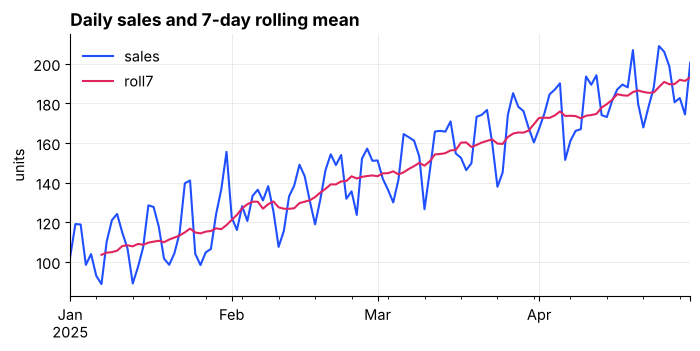

In [11]:
import matplotlib.pyplot as plt
feat = sales.to_frame()
feat["roll7"] = sales.rolling(window=7).mean()
feat["lag1"] = sales.shift(1)
feat["diff1"] = sales.diff()
feat["pct"] = sales.pct_change()
print(feat.iloc[6:10].round(2))
ax = feat[["sales", "roll7"]].plot(figsize=(8, 3.4), title="Daily sales and 7-day rolling mean")
ax.set_ylabel("units")
plt.show()

## 13.6 Method chaining: a full mini-analysis · *Intermediate*

**From raw file to report table in one readable chain**

In [12]:
report = (pd.read_csv("insurance.csv")
          .dropna(subset=["bmi"])
          .assign(obese=lambda d: d["bmi"] >= 30,
                  age_band=lambda d: pd.cut(d["age"], [17, 35, 50, 64]))
          .groupby(["age_band", "smoker"], observed=True)
          .agg(n=("charges", "size"), median_charges=("charges", "median"),
               obese_rate=("obese", "mean"))
          .round(2)
          .reset_index())
print(report)

   age_band smoker    n  median_charges  obese_rate
0  (17, 35]     no  311        13444.08        0.50
1  (17, 35]    yes   65        35744.29        0.46
2  (35, 50]     no  249        17405.12        0.52
3  (35, 50]    yes   60        41077.34        0.43
4  (50, 64]     no  220        21353.54        0.39
5  (50, 64]    yes   55        43822.52        0.45


## Try it yourself

1. For each region, find the share of customers who are smokers and the median charge for smokers vs non-smokers in one table.
2. Make a long-format table of `age`, `bmi` and `charges` with `melt`, then compute each variable's mean with `groupby`.
3. Resample `sales` to weekly sums and plot them.

Worked solutions: [solutions-parts-1-4.ipynb](../../solutions/solutions-parts-1-4.ipynb), section *Chapter 13*.